# Lab 5: k-NN and SVM

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

knndata = pd.read_csv("./knndata.txt")

In [2]:
X = knndata.loc[:, ["X1", "X2"]]
y = knndata.Y

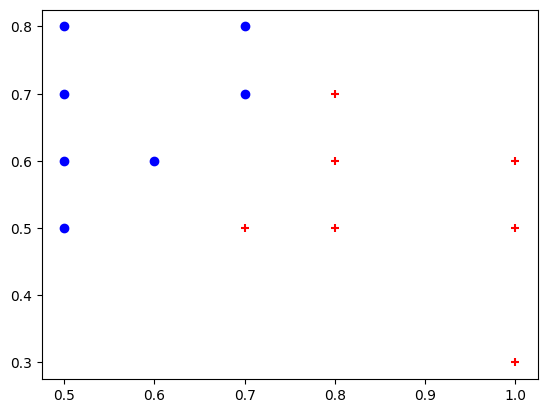

In [3]:
plt.scatter(X[(y == 2)].X1, X[(y == 2)].X2, c="red", marker="+")
plt.scatter(X[(y == 1)].X1, X[(y == 1)].X2, c="blue", marker="o")
plt.show()

In [4]:
from sklearn.neighbors import KNeighborsClassifier
clf = KNeighborsClassifier(n_neighbors=1)
clf = clf.fit(X, y)
print(clf.predict([[0.7, 0.4]]))
print(clf.predict_proba([[0.7, 0.4]]))

[2]
[[0. 1.]]


.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [5]:
clf = KNeighborsClassifier(n_neighbors=5)
clf = clf.fit(X, y)
print(clf.predict([[0.7, 0.4]]))
print(clf.predict_proba([[0.7, 0.4]]))

[2]
[[0.4 0.6]]


.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [6]:
clf = KNeighborsClassifier(n_neighbors=3)
clf = clf.fit(X, y)
print(clf.predict([[0.7, 0.6]]))
print(clf.predict_proba([[0.7, 0.6]]))

[1]
[[0.66666667 0.33333333]]


.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [7]:
alldata = pd.read_csv("./alldata.txt")

In [8]:
xtrain = alldata.loc[0:600, ["X1", "X2"]]
ytrain = alldata.loc[0:600, "y"]

In [9]:
xtest = alldata.loc[600:800, ["X1", "X2"]]
ytest = alldata.loc[600:800, "y"]

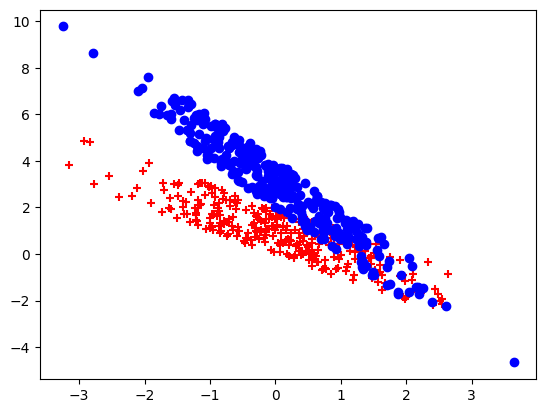

In [10]:
plt.scatter(xtrain[(ytrain == 2)].X1, xtrain[(ytrain == 2)].X2, c="red", marker="+")
plt.scatter(xtrain[(ytrain == 1)].X1, xtrain[(ytrain == 1)].X2, c="blue", marker="o")
plt.show()

In [11]:
X1 = np.arange (min(xtrain.X1.tolist()), max(xtrain.X1.tolist()), 0.01)
X2 = np.arange (min(xtrain.X2.tolist()), max(xtrain.X2.tolist()), 0.01)
xx, yy = np.meshgrid(X1, X2)

.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


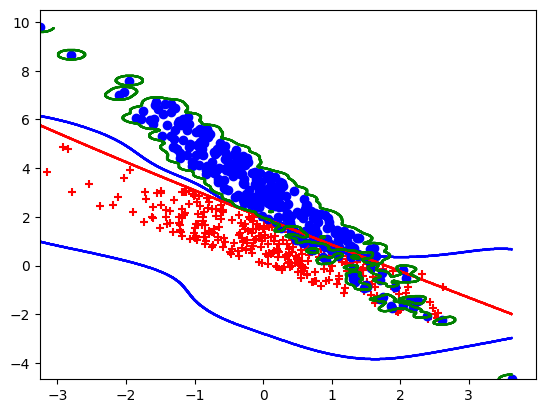

In [12]:
from sklearn import svm
from sklearn.metrics import accuracy_score
clf = svm.SVC(kernel="rbf", gamma=1)
clf = clf.fit(xtrain, ytrain)
pred = clf.predict(np.c_[xx.ravel(), yy.ravel()])
pred = pred.reshape(xx.shape)
plt.contour(xx, yy, pred, colors="blue")

clf = svm.SVC(kernel="rbf", gamma=0.01)
clf = clf.fit(xtrain, ytrain)
pred = clf.predict(np.c_[xx.ravel(), yy.ravel()])
pred = pred.reshape(xx.shape)
plt.contour(xx, yy, pred, colors="red")

clf = svm.SVC(kernel="rbf", gamma=100)
clf = clf.fit(xtrain, ytrain)
pred = clf.predict(np.c_[xx.ravel(), yy.ravel()])
pred = pred.reshape(xx.shape)
plt.contour(xx, yy, pred, colors="green")

plt.scatter(xtrain[(ytrain == 2)].X1, xtrain[(ytrain == 2)].X2, c="red", marker="+")
plt.scatter(xtrain[(ytrain == 1)].X1, xtrain[(ytrain == 1)].X2, c="blue", marker="o")
plt.show()

In [13]:
gammavalues = [0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]

In [14]:
trainingError = []
testingError = []
for gamma in gammavalues:
    clf = svm.SVC(kernel="rbf", gamma=gamma)
    clf = clf.fit(xtrain, ytrain)
    pred = clf.predict(xtrain)
    trainingError.append(1 - accuracy_score(ytrain, pred))
    pred = clf.predict(xtest)
    testingError.append(1 - accuracy_score(ytest, pred))

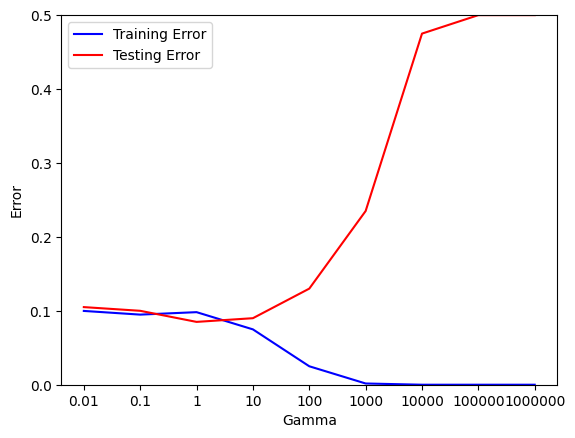

In [15]:
plt.plot(trainingError, c="blue")
plt.plot(testingError, c="red")
plt.ylim(0, 0.5)
plt.xticks(range(len(gammavalues)), gammavalues)
plt.legend(["Training Error", "Testing Error"])
plt.xlabel("Gamma")
plt.ylabel("Error")
plt.show()

In [16]:
from sklearn.model_selection import cross_val_score
accuracies = []
for gamma in gammavalues:
    clf = svm.SVC(kernel="rbf", gamma=gamma)
    scores = cross_val_score(clf, xtrain, ytrain, cv=10)
    accuracies.append(scores.mean())

In [17]:
print("Best gamma: ", gammavalues[np.argmax(accuracies)])

Best gamma:  0.1
